In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!


In [4]:
df = pd.read_csv("retail_sales_dataset.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())


Dataset loaded successfully!
Rows and columns: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [5]:

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Column names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [6]:

print("Missing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)


Missing values in each column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate rows:
0

Data types:
Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object


In [7]:

total_sales = df["Total Amount"].sum()
total_transactions = df["Transaction ID"].nunique()
total_customers = df["Customer ID"].nunique()

print(f"Total Sales: ₹{total_sales:,.2f}")
print(f"Total Transactions: {total_transactions}")
print(f"Unique Customers: {total_customers}")


Total Sales: ₹456,000.00
Total Transactions: 1000
Unique Customers: 1000


In [8]:
df["Date"] = pd.to_datetime(df["Date"])

print("Date column converted successfully!")
print(df.dtypes)


Date column converted successfully!
Transaction ID               int64
Date                datetime64[ns]
Customer ID                 object
Gender                      object
Age                          int64
Product Category            object
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object


In [9]:
df["Calculated Amount"] = df["Quantity"] * df["Price per Unit"]

df["Difference"] = df["Total Amount"] - df["Calculated Amount"]

print("Number of mismatched transactions:",
      (df["Difference"] != 0).sum())

Number of mismatched transactions: 0


In [10]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Month Name"] = df["Date"].dt.strftime("%B")

display(df[["Date", "Year", "Month", "Month Name"]].head())

,Date,Year,Month,Month Name
0,2023-11-24,2023,11,November
1,2023-02-27,2023,2,February
2,2023-01-13,2023,1,January
3,2023-05-21,2023,5,May
4,2023-05-06,2023,5,May


In [11]:
category_sales = df.groupby("Product Category")["Total Amount"].sum()

print(category_sales)

Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64


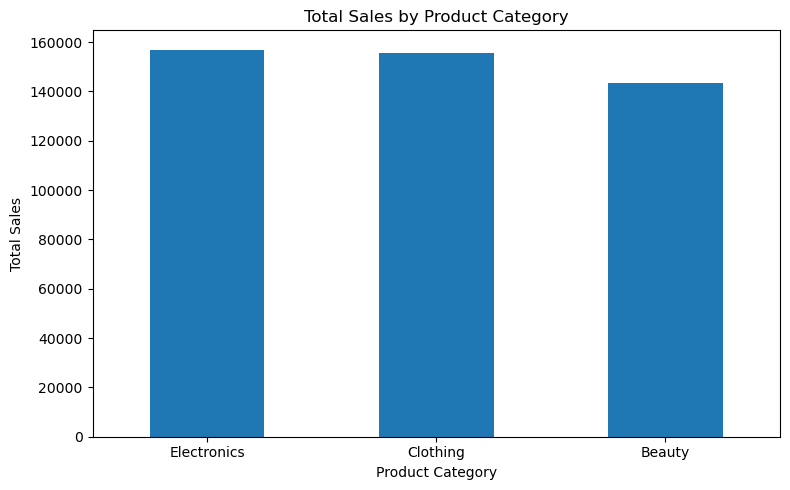

In [12]:
import matplotlib.pyplot as plt

category_sales = category_sales.sort_values(ascending=False)

category_sales.plot(kind="bar", figsize=(8, 5))

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
top_category = category_sales.idxmax()
highest_sales = category_sales.max()

print("Top-selling category:", top_category)
print(f"Total sales: ₹{highest_sales:,.2f}")

Top-selling category: Electronics
Total sales: ₹156,905.00


In [14]:
monthly_sales = df.groupby("Month Name")["Total Amount"].sum()

print(monthly_sales)

Month Name
April        33870
August       36960
December     44690
February     44060
January      36980
July         35465
June         36715
March        28990
May          53150
November     34920
October      46580
September    23620
Name: Total Amount, dtype: int64


In [15]:
monthly_sales = df.groupby(
    df["Date"].dt.to_period("M")
)["Total Amount"].sum()

print(monthly_sales)

Date
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64


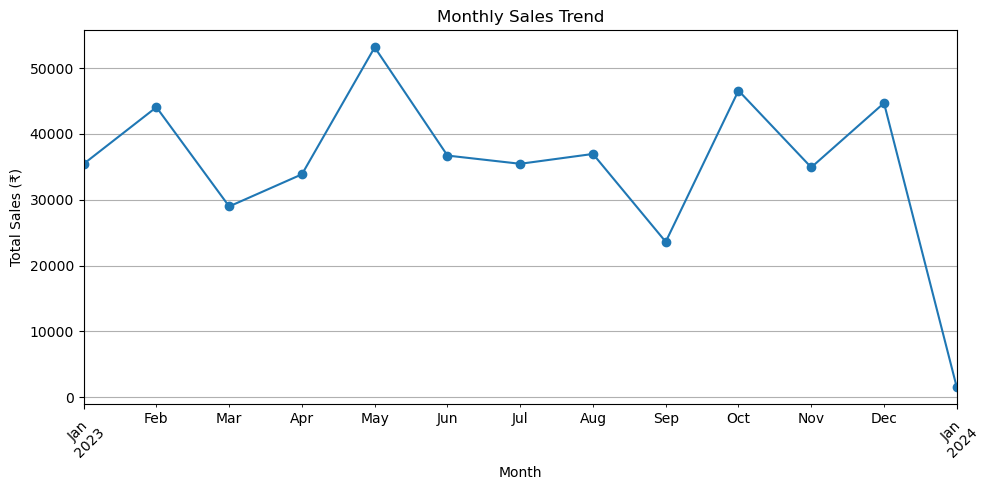

In [16]:
import matplotlib.pyplot as plt

monthly_sales.plot(kind="line", marker="o", figsize=(10, 5))

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [17]:
best_month = monthly_sales.idxmax()
highest_month_sales = monthly_sales.max()

print("Month with highest sales:", best_month)
print(f"Highest monthly sales: ₹{highest_month_sales:,.2f}")

Month with highest sales: 2023-05
Highest monthly sales: ₹53,150.00


In [18]:
gender_sales = df.groupby("Gender")["Total Amount"].sum()

print(gender_sales)

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


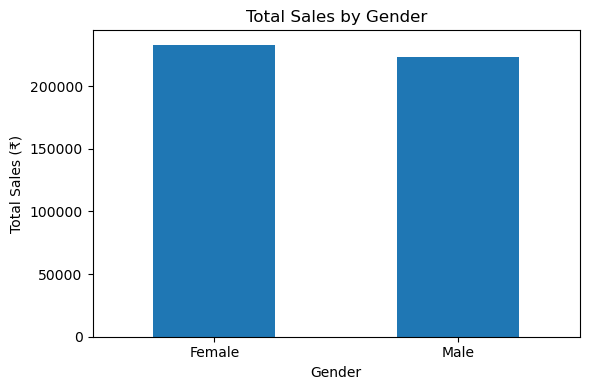

In [19]:
import matplotlib.pyplot as plt

gender_sales.plot(kind="bar", figsize=(6, 4))

plt.title("Total Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [20]:
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[0, 20, 30, 40, 50, 100],
    labels=["Below 20", "20–29", "30–39", "40–49", "50+"],
    right=False
)

age_sales = df.groupby(
    "Age Group", observed=False
)["Total Amount"].sum()

print(age_sales)

Age Group
Below 20     26085
20–29        97070
30–39        96325
40–49        93365
50+         143155
Name: Total Amount, dtype: int64


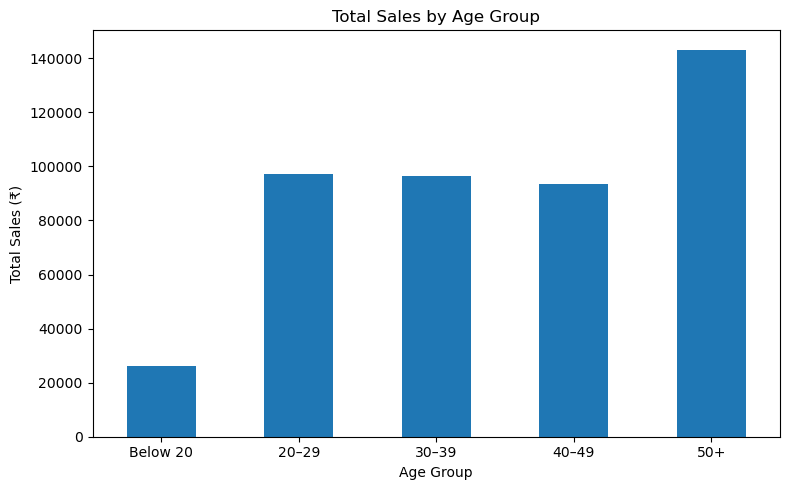

In [21]:
age_sales.plot(kind="bar", figsize=(8, 5))

plt.title("Total Sales by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [22]:
best_age_group = age_sales.idxmax()
highest_age_sales = age_sales.max()

print("Highest-sales age group:", best_age_group)
print(f"Total sales: ₹{highest_age_sales:,.2f}")

Highest-sales age group: 50+
Total sales: ₹143,155.00


In [23]:
category_quantity = df.groupby("Product Category")["Quantity"].sum()

category_quantity = category_quantity.sort_values(ascending=False)

print(category_quantity)

Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64


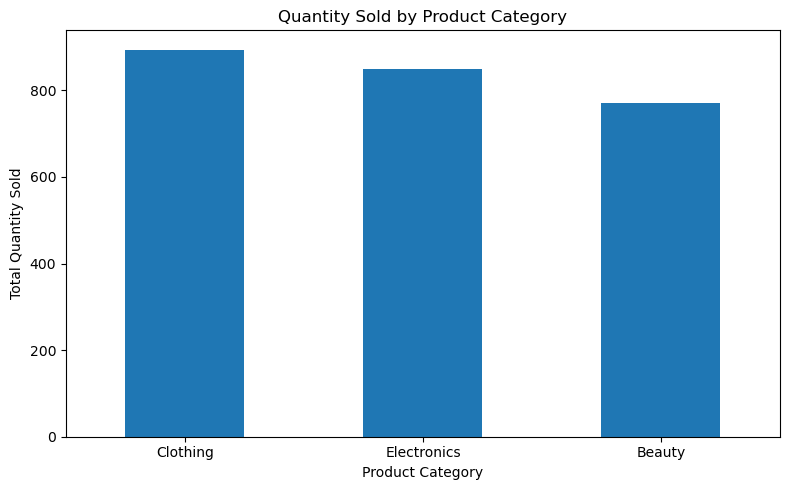

In [24]:
category_quantity.plot(kind="bar", figsize=(8, 5))

plt.title("Quantity Sold by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Quantity Sold")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [25]:
average_sales = df.groupby("Product Category")["Total Amount"].mean()

average_sales = average_sales.sort_values(ascending=False)

print(average_sales)

Product Category
Beauty         467.475570
Electronics    458.786550
Clothing       443.247863
Name: Total Amount, dtype: float64


In [26]:
best_average_category = average_sales.idxmax()
highest_average = average_sales.max()

print("Category with highest average transaction value:",
      best_average_category)

print(f"Average transaction value: ₹{highest_average:,.2f}")

Category with highest average transaction value: Beauty
Average transaction value: ₹467.48


In [27]:
# Overall sales
total_sales = df["Total Amount"].sum()

# Best-selling category by total revenue
category_sales = df.groupby("Product Category")["Total Amount"].sum()
top_category = category_sales.idxmax()

# Category with the highest quantity sold
category_quantity = df.groupby("Product Category")["Quantity"].sum()
top_quantity_category = category_quantity.idxmax()

# Gender with the highest total sales
gender_sales = df.groupby("Gender")["Total Amount"].sum()
top_gender = gender_sales.idxmax()

# Age group with the highest total sales
age_sales = df.groupby("Age Group", observed=False)["Total Amount"].sum()
top_age_group = age_sales.idxmax()

# Month with the highest sales
monthly_sales = df.groupby(df["Date"].dt.to_period("M"))["Total Amount"].sum()
best_month = monthly_sales.idxmax()

print("===== RETAIL SALES BUSINESS INSIGHTS =====")
print(f"Total Revenue: ₹{total_sales:,.2f}")
print(f"Highest Revenue Category: {top_category}")
print(f"Most Units Sold Category: {top_quantity_category}")
print(f"Gender with Highest Sales: {top_gender}")
print(f"Age Group with Highest Sales: {top_age_group}")
print(f"Best Sales Month: {best_month}")

===== RETAIL SALES BUSINESS INSIGHTS =====
Total Revenue: ₹456,000.00
Highest Revenue Category: Electronics
Most Units Sold Category: Clothing
Gender with Highest Sales: Female
Age Group with Highest Sales: 50+
Best Sales Month: 2023-05
